# Лабораторная работа №3: Метрики качества, кросс-валидация и пайплайны
## Импорт библиотек

In [1]:
import pandas as pd 
import numpy as np 

# Инструменты для пайплайна и валидации
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

# Инструменты предобработки
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

#Модель классификации
from sklearn.neighbors import KNeighborsClassifier

#Бизнес-метрики качества
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix

In [2]:
df = pd.read_csv('insurance.csv')
# преобразуем признак smoker из yes-no в 1-0
df['smoker'] = df['smoker'].map({'yes': 1, 'no': 0})
# баланс классов (целевая переменная - smoker: 1 - курящий, 0 - некурящий)
class_counts = df["smoker"].value_counts(normalize=True) * 100
print(f"Баланс классов:\nВысокие мед расходы - {class_counts[1]:.1f}%\nНизкие мед расходы - {class_counts[0]:.1f}%")

# делим выборку
X = df.drop("smoker", axis = 1)
y = df["smoker"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state=42, stratify=y)
print(df.columns)

Баланс классов:
Высокие мед расходы - 20.5%
Низкие мед расходы - 79.5%
Index(['age', 'sex', 'bmi', 'children', 'smoker', 'region', 'charges'], dtype='str')


### В датасете 20,5% курящих и 79,5% некурящих клиентов, что указывает на несбалансированность классов. Разделение данных выполнено в соотношении 80/20 с использованием stratify=y, благодаря чему пропорции классов сохраняются в обучающей и тестовой выборках, что позволяет корректнее оценить качество классификатора

In [3]:
numeric_features = ['age', 'bmi', 'children', 'charges']
categorical_features = ['sex', 'children', 'region']

# Ветка 1: обработка чисел
numeric_transformer = Pipeline(
    steps=[("imputer", SimpleImputer(strategy="median")),
           ("scaler", StandardScaler())]
)    

# Ветка 2: обработка категорий (текста)
categorical_transformer = Pipeline(
    steps =[
        ("imputer", SimpleImputer(strategy="most_frequent")),
         ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ]
)

# 1 + 2
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

# Итоговый конвейер: Предобработка -> Модель
clf_pipline = Pipeline(
    steps =[
        ("preprocessor", preprocessor),
        ("classifier", KNeighborsClassifier())
    ]
)

param_grid = {
    "classifier__n_neighbors": [3,5,9],
    "classifier__weights": ["uniform", "distance"]
}

# 5-Fold кросс-валидация
cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# сбор всего в одно
grid_search = GridSearchCV(
    estimator=clf_pipline,
    param_grid=param_grid,
    cv = cv_strategy,
    scoring="roc_auc",
    n_jobs=-1
)

grid_search.fit(X_train, y_train)
best_model = grid_search.best_estimator_
print(f'\nЛучшие параметры алгоритма: {grid_search.best_params_}')


Лучшие параметры алгоритма: {'classifier__n_neighbors': 9, 'classifier__weights': 'distance'}


In [4]:
# предскажем 0 или 1
y_pred = best_model.predict(X_test)
# предсказание вероятностей от 0.0 до 1.0 (для ROC-AUC)
y_proba = best_model.predict_proba(X_test)[:, 1]

print("---Матрица ошибок---")
conf_matrix = confusion_matrix(y_test, y_pred)
print(f"Истинно отрицательные (TN - некурящий, мед расходы низкие) {conf_matrix[0][0]}") # ???
print(f"Ложноположительные (FP - некурящий, мед расходы высокие) {conf_matrix[0][1]}")
print(f"Ложноотрицательные (FN - курящий, мед расходы низкие) {conf_matrix[1][0]}")
print(f"Истинно отрицательные (TP - курящий, мед расходы высокие) {conf_matrix[1][1]}")

print("---Отчет по метрикам---")
print(classification_report(y_test, y_pred, target_names=["Некурящий (0)", "Курящий (1)"]))

roc_auc = roc_auc_score(y_test, y_proba)
print(f"Площадь под кривой ROC-AUC: {roc_auc:.4f}")

---Матрица ошибок---
Истинно отрицательные (TN - некурящий, мед расходы низкие) 210
Ложноположительные (FP - некурящий, мед расходы высокие) 3
Ложноотрицательные (FN - курящий, мед расходы низкие) 19
Истинно отрицательные (TP - курящий, мед расходы высокие) 36
---Отчет по метрикам---
               precision    recall  f1-score   support

Некурящий (0)       0.92      0.99      0.95       213
  Курящий (1)       0.92      0.65      0.77        55

     accuracy                           0.92       268
    macro avg       0.92      0.82      0.86       268
 weighted avg       0.92      0.92      0.91       268

Площадь под кривой ROC-AUC: 0.9561


Модель правильно определила 210 некурящих и 36 курящих клиентов. При этом 3 некурящих клиента ошибочно отнесены к курящим, а 19 курящих - к некурящим, модель лучше определяет некурящих клиентов, но пропускает часть курящих, что может приводить к недооценке медицинских расходов.

# Предсказание суммы мед расходов

In [5]:
from sklearn.model_selection import RandomizedSearchCV, KFold
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error

In [6]:
df_reg = df.dropna(subset=["bmi", "children"]).copy()
X_reg = df_reg[["age", "bmi", "children"]]
y_reg = df_reg["charges"]

X_train_r, X_test_r, y_train_r, y_test_r = train_test_split(X_reg, y_reg, test_size=0.2, random_state=42)

reg_pipline = Pipeline(
    [("scaler", StandardScaler()), ("knn_reg", KNeighborsRegressor())]
)
kf = KFold(n_splits=5, shuffle=True, random_state=42)
param_dist = {
    "knn_reg__n_neighbors": np.arange(3,30),
    "knn_reg__weights": ["uniform", "distance"]
}
random_search = RandomizedSearchCV(
    estimator=reg_pipline,
    param_distributions=param_dist,
    n_iter = 10,
    cv=kf,
    scoring="neg_mean_absolute_error",
    random_state=42,
    n_jobs=1
)

random_search.fit(X_train_r, y_train_r)
best_reg = random_search.best_estimator_
print(f'\nЛучшие параметры алгоритма: {random_search.best_params_}')


Лучшие параметры алгоритма: {'knn_reg__weights': 'uniform', 'knn_reg__n_neighbors': np.int64(27)}


In [7]:
y_pred_r = best_reg.predict(X_test_r)
def smape(y_test, y_pred):
    return 100* np.mean(
        2 * np.abs(y_pred-y_test)/(np.abs(y_test)+np.abs(y_pred))
    )
mse = mean_squared_error(y_test_r, y_pred_r)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_test_r, y_pred_r)
smape_value = smape (y_test_r, y_pred_r)

print("--- Отчет по метрикам регрессии ---")
print(f"MSE (квадратные $) {mse:,.0f}")
print(f"RMSE ($) {rmse:,.0f}")
print(f"MAE (Средняя ошибка) {mae:,.2f}")
print(f"SMAPE (ошибка в %) {smape_value:,.2f}%")

--- Отчет по метрикам регрессии ---
MSE (квадратные $) 135,085,905
RMSE ($) 11,623
MAE (Средняя ошибка) 9,114.98
SMAPE (ошибка в %) 72.60%


### Проверяем качество лучшей модели на тестовой выборке с помощью четырёх метрик: 
#### MSE = 135,085,905 квадратных $ - средняя квадратичная ошибка, сильнее штрафует большие отклонения; 
#### RMSE = 11,623 $ - квадратный корень из MSE, выраженный в тех же единицах, что и целевой признак; 
#### MAE = 9,114.98 - средняя абсолютная ошибка прогноза; 
#### SMAPE = 72.60% - симметричная средняя абсолютная процентная ошибка
#### Чем меньше значения этих метрик, тем ближе прогнозы к фактическим значениям

# Визуальный анализ

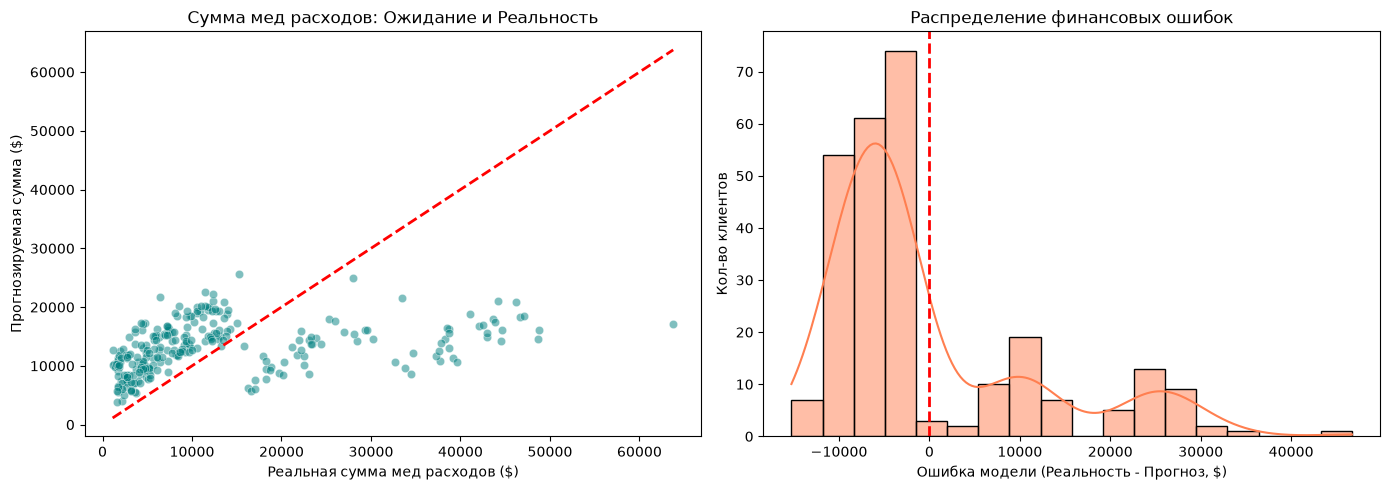

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots (1,2, figsize=(14,5))

sns.scatterplot(x=y_test_r, y=y_pred_r, alpha=0.5, color="teal", ax=axes[0])
y_min = min(y_test_r.min(), y_pred_r.min())
y_max = max(y_test_r.max(), y_pred_r.max())
axes[0].plot(
    [y_min, y_max], [y_min, y_max], 'r--', lw = 2
)
axes[0].set_title("Сумма мед расходов: Ожидание и Реальность")
axes[0].set_xlabel("Реальная сумма мед расходов ($)")
axes[0].set_ylabel("Прогнозируемая сумма ($)")

residuals = y_test_r - y_pred_r
sns.histplot(residuals, kde=True, color='coral', ax = axes[1])
axes[1].axvline(x=0, color='red', linestyle = '--', lw=2)
axes[1].set_title("Распределение финансовых ошибок")
axes[1].set_xlabel("Ошибка модели (Реальность - Прогноз, $)")
axes[1].set_ylabel("Кол-во клиентов")

plt.tight_layout()
plt.show()

### На графике фактических и прогнозируемых расходов видно, что модель недостаточно точно оценивает большие суммы и чаще завышает небольшие расходы. Распределение ошибок показывает преобладание отрицательных значений, то есть модель чаще завышает прогнозируемые расходы относительно фактических. Получается, модель имеет ограниченную точность и нуждается в дополнительной настройке

## Финальный экономический вывод
### Модель классификации показала Accuracy 0,92 и ROC-AUC 0,9561. При этом допущено 3 ошибки 1 рода (FP) и 19 ошибок 2 рода (FN). Первые могут привести к необоснованному завышению оценки расходов некурящих клиентов, а вторые к недооценке расходов курящих клиентов и финансовым потерям страховой компании. Precision для класса курящих составляет 0,92, а Recall - 0,65. Чтобы выявлять больше курящих клиентов, можно повысить чувствительность модели, однако это может увеличить число ложноположительных результатов. Выбор баланса зависит от стоимости каждого типа ошибки для бизнеса. Модель можно использовать для предварительного анализа клиентов, но перед практическим внедрением необходимо улучшить Recall и оценить финансовые последствия ошибок. Регрессионная модель показала MAE около 9 150,89 долларов и SMAPE 71,18%, что указывает на значительную погрешность прогнозирования. Поэтому её целесообразно использовать для предварительной оценки расходов, но не как единственный инструмент принятия финансовых решений
### Обе модели полезны для анализа данных, однако для полноценного применения в бизнесе требуется дополнительная настройка и проверка качества прогнозов